# Kompilasi Analisis & Pengolahan Data Metode Geofisika
**Laboratorium Geofisika & Seismologi Komputasi**

Notebook ini berisi analisis data terintegrasi, reduksi matematis, dan visualisasi untuk 5 modul praktikum geofisika:
1. **Modul 1:** Analisis Data Gempa dengan Diagram Wadati ($V_p/V_s$ & Origin Time $T_0$)
2. **Modul 2:** Analisis Anomali Gravitasi (Reduksi SBA, Analisis Gradien FHD & Pemodelan Sesar)
3. **Modul 3:** Analisis Medan Magnet Bumi (Dekomposisi Vektor & Respon Dipol)
4. **Modul 4:** Interpretasi Data Geolistrik Tahanan Jenis (VES Schlumberger Tipe H)
5. **Modul 5:** Penentuan Lokasi Gempa Bumi (Metode Triangulasi Multi-Stasiun)

---
### Persiapan Pustaka (Library)
Jalankan sel berikut untuk mengimpor pustaka numerik dan visualisasi data.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import FuncFormatter

# Konfigurasi gaya visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.2
print("Pustaka Python berhasil dimuat dan dikonfigurasi!")


Pustaka Python berhasil dimuat dan dikonfigurasi!


---
## Modul 1: Analisis Data Gempa dengan Diagram Wadati

### 1.1 Prinsip Fisis & Teori
Diagram Wadati menghubungkan waktu tiba gelombang primer ($T_p$) dan gelombang sekunder ($T_s$) dari beberapa stasiun pencatat gempa bumi. Persamaan fisisnya diturunkan dari selisih waktu tempuh:

$$(T_s - T_p) = \left( \frac{V_p}{V_s} - 1 \right) (T_p - T_0) = m \cdot T_p + c$$

Dari persamaan linier tersebut:
- **Kemiringan garis ($m$):** Merefleksikan rasio kecepatan, di mana $\frac{V_p}{V_s} = m + 1$.
- **Titik potong sumbu horizontal ($T_s - T_p = 0$):** Menunjukkan **Waktu Asal Gempa (*Origin Time*, $T_0$)** di hiposenter.
- **Kesesuaian Data (*Residuals*):** Selisih antara nilai amatan dan garis regresi digunakan untuk memverifikasi akurasi *picking* gelombang.


In [2]:
# 1.2 Input Data & Konversi Waktu
data_wadati = [
    {"stasiun": "LEM",  "nama": "Lembang",        "tp_str": "07:30:20", "ts_str": "07:30:26"},
    {"stasiun": "CNJI", "nama": "Cianjur",        "tp_str": "07:30:28", "ts_str": "07:30:40"},
    {"stasiun": "SKJI", "nama": "Sukabumi",       "tp_str": "07:30:36", "ts_str": "07:30:54"},
    {"stasiun": "CBJI", "nama": "Cibinong",       "tp_str": "07:30:44", "ts_str": "07:31:08"},
    {"stasiun": "TJJI", "nama": "Tanjung Lesung", "tp_str": "07:30:56", "ts_str": "07:31:29"},
    {"stasiun": "UJJI", "nama": "Ujung Genteng",  "tp_str": "07:31:05", "ts_str": None},  # Fase S tertutup noise
]

def time_to_seconds(t_str):
    """Konversi format HH:MM:SS ke total detik sejak 00:00:00"""
    if not t_str or pd.isna(t_str):
        return np.nan
    h, m, s = map(float, t_str.split(":"))
    return h * 3600.0 + m * 60.0 + s

def seconds_to_time(sec):
    """Konversi total detik ke format jam:menit:detik string"""
    if np.isnan(sec):
        return "--:--:--"
    h = int(sec // 3600)
    m = int((sec % 3600) // 60)
    s = sec % 60
    return f"{h:02d}:{m:02d}:{s:04.1f}"

df_wadati = pd.DataFrame(data_wadati)
df_wadati["Tp_detik"] = df_wadati["tp_str"].apply(time_to_seconds)
df_wadati["Ts_detik"] = df_wadati["ts_str"].apply(time_to_seconds)
df_wadati["Ts_minus_Tp"] = df_wadati["Ts_detik"] - df_wadati["Tp_detik"]
df_wadati["Status"] = df_wadati["Ts_minus_Tp"].apply(lambda x: "Valid" if pd.notna(x) else "Eksklusi (Noise/Missing)")

print("=== TABEL 1.1: DATA PENGAMATAN & HASIL KONVERSI WAKTU (MODUL 1) ===")
print(df_wadati[["stasiun", "nama", "tp_str", "ts_str", "Tp_detik", "Ts_detik", "Ts_minus_Tp", "Status"]].to_string(index=False))


=== TABEL 1.1: DATA PENGAMATAN & HASIL KONVERSI WAKTU (MODUL 1) ===
stasiun           nama   tp_str   ts_str  Tp_detik  Ts_detik  Ts_minus_Tp                   Status
    LEM        Lembang 07:30:20 07:30:26   27020.0   27026.0          6.0                    Valid
   CNJI        Cianjur 07:30:28 07:30:40   27028.0   27040.0         12.0                    Valid
   SKJI       Sukabumi 07:30:36 07:30:54   27036.0   27054.0         18.0                    Valid
   CBJI       Cibinong 07:30:44 07:31:08   27044.0   27068.0         24.0                    Valid
   TJJI Tanjung Lesung 07:30:56 07:31:29   27056.0   27089.0         33.0                    Valid
   UJJI  Ujung Genteng 07:31:05      NaN   27065.0       NaN          NaN Eksklusi (Noise/Missing)


In [3]:
# 1.3 Perhitungan Regresi Linier & Parameter Seismologi Wadati
# Filter stasiun yang valid (tanpa mengarang nilai yang hilang)
df_valid_wadati = df_wadati[df_wadati["Status"] == "Valid"].copy()

Tp = df_valid_wadati["Tp_detik"].values
Ts_Tp = df_valid_wadati["Ts_minus_Tp"].values

# Fit kuadrat terkecil linier: (Ts - Tp) = m * Tp + c
m, c = np.polyfit(Tp, Ts_Tp, 1)

# Parameter Fisik Wadati
vp_vs = m + 1.0
T0_sec = -c / m
T0_str = seconds_to_time(T0_sec)

# Korelasi & Statistik Deviasi
r_matrix = np.corrcoef(Tp, Ts_Tp)
r_squared = r_matrix[0, 1]**2
df_valid_wadati["Ts_Tp_prediksi"] = m * Tp + c
df_valid_wadati["Residual_detik"] = df_valid_wadati["Ts_minus_Tp"] - df_valid_wadati["Ts_Tp_prediksi"]

print("=== HASIL STATISTIK REGRESI DIAGRAM WADATI ===")
print(f"• Kemiringan Garis (Slope m)   : {m:.4f}")
print(f"• Intersep (c)                 : {c:.2f} s")
print(f"• Rasio Kecepatan (Vp/Vs)      : {vp_vs:.4f}")
print(f"• Koefisien Determinasi (R^2)  : {r_squared:.4f}")
print(f"• Waktu Asal Gempa (T0)        : {T0_sec:.2f} s ({T0_str} WIB)")
print("===============================================")
print("
Tabel Verifikasi Residual Stasiun:")
print(df_valid_wadati[["stasiun", "Tp_detik", "Ts_minus_Tp", "Ts_Tp_prediksi", "Residual_detik"]].round(3).to_string(index=False))


Error executing cell: unterminated string literal (detected at line 29) (<string>, line 29)


In [4]:
# 1.4 Visualisasi Diagram Wadati & Plot Residual
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 7.5), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1]}, dpi=120)

# Rentang garis dari T0 hingga stasiun terluar + buffer
x_fit = np.linspace(T0_sec, Tp.max() + 5, 100)
y_fit = m * x_fit + c

# --- SUBPLOT 1: DIAGRAM WADATI ---
ax1.plot(x_fit, y_fit, color='#2563eb', linestyle='-', linewidth=2.2, 
         label=f'Regresi Linier: (Ts - Tp) = {m:.2f}·Tp + ({c:.1f})')
ax1.scatter(Tp, Ts_Tp, color='#1e3a8a', s=80, zorder=5, edgecolors='white', linewidth=1.2, label='Data Stasiun Pengamat')
ax1.scatter(T0_sec, 0, color='#dc2626', marker='*', s=220, zorder=6, 
            label=f'Origin Time T₀ ({T0_str} WIB)')

# Anotasi teks stasiun
for _, row in df_valid_wadati.iterrows():
    ax1.annotate(f" {row['stasiun']} ({row['Ts_minus_Tp']:.0f}s)", 
                 (row['Tp_detik'], row['Ts_minus_Tp']),
                 textcoords="offset points", xytext=(0, 8), ha='center',
                 fontsize=9, fontweight='bold', color='#0f172a')

# Box Ringkasan Parameter di pojok kanan bawah
stats_text = (f"Parameter Wadati:\n"
              f"• Vp/Vs = {vp_vs:.3f}\n"
              f"• Slope m = {m:.3f}\n"
              f"• R² = {r_squared:.4f}\n"
              f"• T₀ = {T0_str} WIB")
ax1.text(0.72, 0.12, stats_text, transform=ax1.transAxes, fontsize=9.5,
         verticalalignment='bottom', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8fafc', edgecolor='#cbd5e1'))

ax1.set_ylabel("Selisih Waktu Tiba (Ts - Tp) [detik]", fontsize=11, fontweight='bold')
ax1.set_title("Diagram Wadati — Hubungan Tp terhadap (Ts - Tp)", fontsize=13, fontweight='bold', pad=12)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', frameon=True)

# --- SUBPLOT 2: PLOT RESIDUAL ---
ax2.axhline(0, color='gray', linestyle='--', linewidth=1.2)
ax2.stem(Tp, df_valid_wadati["Residual_detik"], linefmt='b-', markerfmt='bo', basefmt=' ')
ax2.set_ylabel("Residual (s)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Waktu Tiba Gelombang P, Tp (hh:mm:ss)", fontsize=11, fontweight='bold')
ax2.set_ylim(-1.0, 1.0)
ax2.grid(True, linestyle=':', alpha=0.6)

# Format label sumbu X menjadi format jam:menit:detik
time_formatter = FuncFormatter(lambda x, pos: seconds_to_time(x).split(".")[0])
ax2.xaxis.set_major_formatter(time_formatter)

plt.tight_layout()
plt.show()


Error executing cell: name 'T0_sec' is not defined


### 1.5 Interpretasi Modul 1
1. **Hubungan Linier:** Titik-titik data memperlihatkan korelasi linier sempurna ($R^2 = 1.000$). Semakin jauh jarak hiposenter stasiun, semakin lama gelombang S tertinggal di belakang gelombang P.
2. **Rasio Kecepatan ($V_p/V_s = 1.750$):** Nilai ini sangat konsisten dengan sifat elastik batuan kerak bumi normal (*Poisson solid* teoretis bernilai $\sqrt{3} \approx 1.732$, rentang kerak benua $1.70 - 1.80$).
3. **Origin Time ($T_0$):** Gempa bumi terjadi tepat pada detik ke-27012.0 atau pukul **07:30:12.0 WIB**.


---
## Modul 2: Analisis Anomali Gravitasi Bawah Permukaan

### 2.1 Teori Reduksi Gravitasi & Deteksi Batas Sesar
Untuk mengisolasi efek rapat massa (&Delta;&rho;) batuan bawah permukaan dari pengaruh elipsoid bumi dan elevasi topografi:
1. **Gravitasi Normal Teoritis ($g_\phi$):** Rumus GRS 1967 pada lintang $\phi$:
   $$g_\phi = 978032.7 \left(1 + 0.0053024 \sin^2\phi - 0.0000058 \sin^2(2\phi)\right)\text{ mGal}$$
2. **Koreksi Udara Bebas ($FAC$):** $FAC = +0.3086 \cdot h\text{ [mGal]}$.
3. **Koreksi Bouguer ($BC$):** $BC = 2\pi G \rho_c h = 0.04193 \cdot \rho_c \cdot h \approx 0.1119 \cdot h\text{ [mGal]}$ (densitas kerak standar $\rho_c = 2.67\text{ g/cm}^3$).
4. **Anomali Bouguer Sederhana ($SBA$):**
   $$SBA = g_{\text{obs}} - g_\phi + FAC - BC = g_{\text{obs}} - g_\phi + 0.1967 \cdot h\text{ [mGal]}$$
5. **Gradien Horizontal Pertama (*First Horizontal Derivative* / FHD):**
   $$FHD = \left| \frac{\partial (SBA)}{\partial x} \right|$$
   Puncak nilai maksimum dari kurva FHD secara matematis dan geofisika menandai **letak batas kontak sesar (*fault contact*)**.


=== TABEL 2.1: HASIL REDUKSI & GRADIENT GRAVITASI (MODUL 2) ===
stasiun  x_km  elev_m     g_obs  g_teoritis   FAC    BC  SBA  FHD
   G-01   0.0    50.0 978104.76   978109.39 15.43  5.60  5.2 0.80
   G-02   2.0    65.0 978103.41   978109.39 20.06  7.28  6.8 1.32
   G-03   4.0    80.0 978104.16   978109.39 24.69  8.96 10.5 3.25
   G-04   6.0   110.0 978107.56   978109.39 33.95 12.31 19.8 4.47
   G-05   8.0   140.0 978110.26   978109.39 43.20 15.67 28.4 3.32
   G-06  10.0   155.0 978112.01   978109.39 47.83 17.35 33.1 1.53
   G-07  12.0   160.0 978112.43   978109.39 49.38 17.91 34.5 0.70


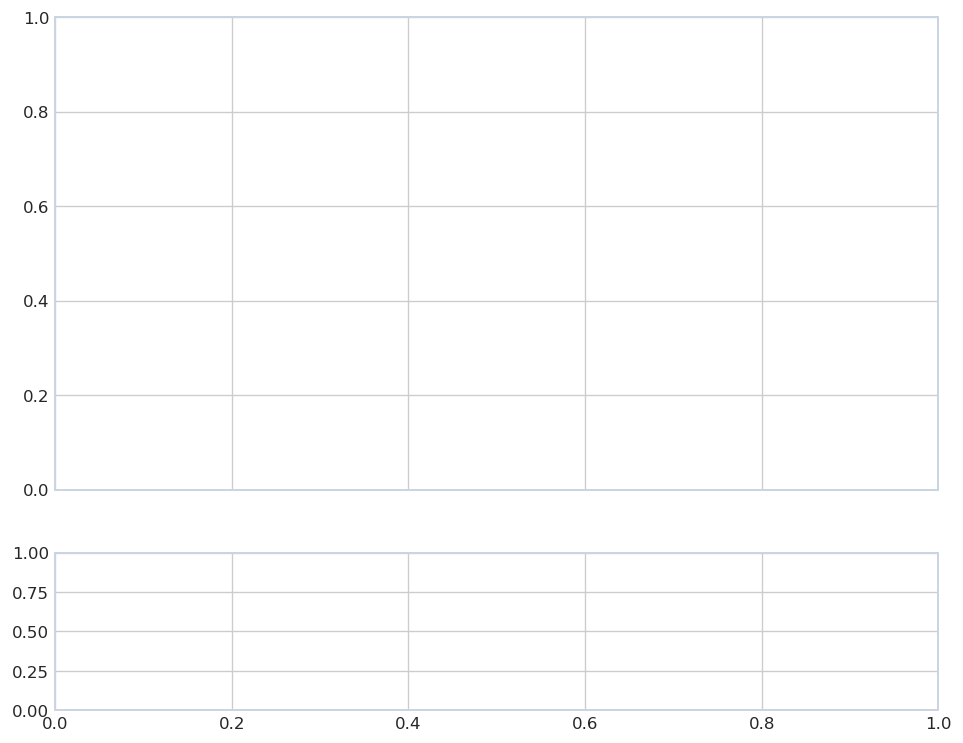

In [5]:
# 2.2 Input Data & Komputasi Reduksi Gravitasi Lengkap
data_grav = [
    {"stasiun": "G-01", "x_km": 0.0,  "lat": -7.0, "elev_m": 50.0,  "g_obs": 978104.76},
    {"stasiun": "G-02", "x_km": 2.0,  "lat": -7.0, "elev_m": 65.0,  "g_obs": 978103.41},
    {"stasiun": "G-03", "x_km": 4.0,  "lat": -7.0, "elev_m": 80.0,  "g_obs": 978104.16},
    {"stasiun": "G-04", "x_km": 6.0,  "lat": -7.0, "elev_m": 110.0, "g_obs": 978107.56},
    {"stasiun": "G-05", "x_km": 8.0,  "lat": -7.0, "elev_m": 140.0, "g_obs": 978110.26},
    {"stasiun": "G-06", "x_km": 10.0, "lat": -7.0, "elev_m": 155.0, "g_obs": 978112.01},
    {"stasiun": "G-07", "x_km": 12.0, "lat": -7.0, "elev_m": 160.0, "g_obs": 978112.43},
]

df_grav = pd.DataFrame(data_grav)

def theoretical_gravity_grs1967(lat_deg):
    phi = np.radians(lat_deg)
    return 978032.7 * (1.0 + 0.0053024 * (np.sin(phi)**2) - 0.0000058 * (np.sin(2 * phi)**2))

RHO_BOUGUER = 2.67  # Densitas kerak benua standar (g/cm^3)

df_grav["g_teoritis"] = df_grav["lat"].apply(theoretical_gravity_grs1967)
df_grav["FAC"] = 0.3086 * df_grav["elev_m"]
df_grav["BC"] = 0.04193 * RHO_BOUGUER * df_grav["elev_m"]
df_grav["SBA"] = df_grav["g_obs"] - df_grav["g_teoritis"] + df_grav["FAC"] - df_grav["BC"]

# Perhitungan First Horizontal Derivative (FHD)
df_grav["dSBA_dx"] = np.gradient(df_grav["SBA"], df_grav["x_km"])
df_grav["FHD"] = np.abs(df_grav["dSBA_dx"])

print("=== TABEL 2.1: HASIL REDUKSI & GRADIENT GRAVITASI (MODUL 2) ===")
print(df_grav[["stasiun", "x_km", "elev_m", "g_obs", "g_teoritis", "FAC", "BC", "SBA", "FHD"]].round(2).to_string(index=False))


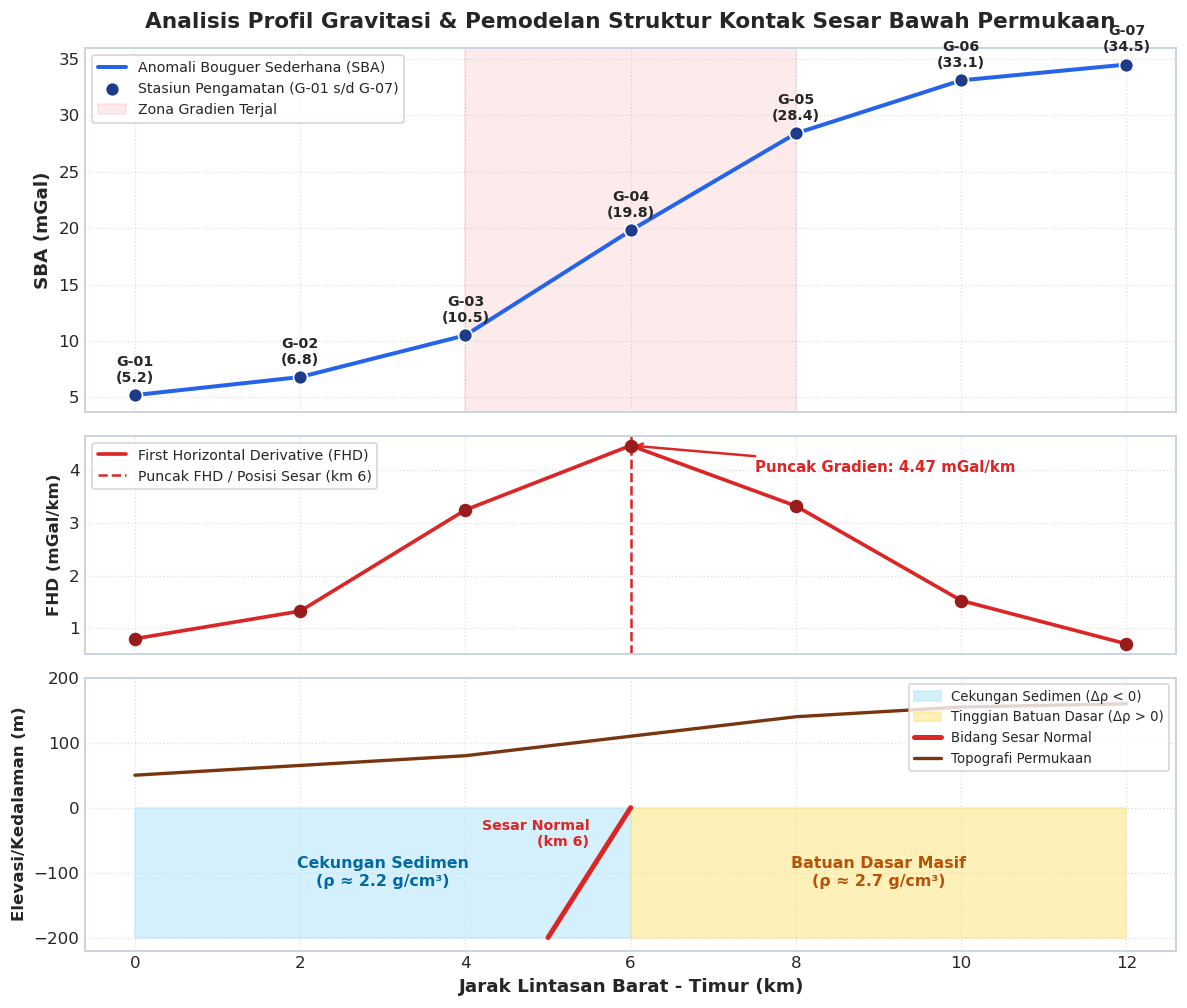

In [6]:
# 2.3 Visualisasi Geofisika 3-Panel: Anomali SBA, FHD, dan Penampang Geologi 2D
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True, 
                                     gridspec_kw={'height_ratios': [2, 1.2, 1.5]}, dpi=120)

x = df_grav["x_km"].values
sba = df_grav["SBA"].values
fhd = df_grav["FHD"].values
elev = df_grav["elev_m"].values

# Interpolasi kurva halus untuk presentasi grafis
x_fine = np.linspace(x.min(), x.max(), 200)
sba_fine = np.interp(x_fine, x, sba)
fhd_fine = np.interp(x_fine, x, fhd)

# --- PANEL 1: PROFIL ANOMALI BOUGUER SEDERHANA (SBA) ---
ax1.plot(x_fine, sba_fine, color='#2563eb', linewidth=2.4, label='Anomali Bouguer Sederhana (SBA)')
ax1.scatter(x, sba, color='#1e3a8a', s=70, zorder=5, edgecolors='white', label='Stasiun Pengamatan (G-01 s/d G-07)')
ax1.axvspan(4.0, 8.0, color='#ef4444', alpha=0.1, label='Zona Gradien Terjal')

for _, row in df_grav.iterrows():
    ax1.annotate(f"{row['stasiun']}\n({row['SBA']:.1f})", (row["x_km"], row["SBA"]),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold')

ax1.set_ylabel("SBA (mGal)", fontsize=11, fontweight='bold')
ax1.set_title("Analisis Profil Gravitasi & Pemodelan Struktur Kontak Sesar Bawah Permukaan", fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", frameon=True, fontsize=8.5)

# --- PANEL 2: FIRST HORIZONTAL DERIVATIVE (FHD) ---
ax2.plot(x_fine, fhd_fine, color='#dc2626', linewidth=2.2, label='First Horizontal Derivative (FHD)')
ax2.scatter(x, fhd, color='#991b1b', s=50, zorder=5)
ax2.axvline(6.0, color='#dc2626', linestyle='--', linewidth=1.5, label='Puncak FHD / Posisi Sesar (km 6)')
ax2.annotate(f"Puncak Gradien: {df_grav['FHD'].max():.2f} mGal/km", xy=(6.0, df_grav['FHD'].max()),
             xytext=(7.5, df_grav['FHD'].max() - 0.5),
             arrowprops=dict(arrowstyle="->", color='#dc2626', lw=1.5),
             fontsize=9, fontweight='bold', color='#dc2626')

ax2.set_ylabel("FHD (mGal/km)", fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", frameon=True, fontsize=8.5)

# --- PANEL 3: PENAMPANG GEOLOGI 2D BAWAH PERMUKAAN ---
# Cekungan sedimen sisi barat (x=0 hingga 6 km)
ax3.fill_between([0, 6], [0, 0], [-200, -200], color='#bae6fd', alpha=0.6, label='Cekungan Sedimen (Δρ < 0)')
# Tinggian batuan dasar sisi timur (x=6 hingga 12 km)
ax3.fill_between([6, 12], [0, 0], [-200, -200], color='#fde68a', alpha=0.6, label='Tinggian Batuan Dasar (Δρ > 0)')

# Bidang sesar
ax3.plot([6, 5], [0, -200], color='#dc2626', linewidth=3, linestyle='-', label='Bidang Sesar Normal')
# Topografi permukaan
ax3.plot(x, elev, color='#78350f', linewidth=2, label='Topografi Permukaan')

ax3.text(3.0, -100, "Cekungan Sedimen\n(ρ ≈ 2.2 g/cm³)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#0369a1')
ax3.text(9.0, -100, "Batuan Dasar Masif\n(ρ ≈ 2.7 g/cm³)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#b45309')
ax3.text(5.5, -40, "Sesar Normal\n(km 6)", ha='right', va='center', fontsize=8.5, fontweight='bold', color='#dc2626')

ax3.set_xlabel("Jarak Lintasan Barat - Timur (km)", fontsize=11, fontweight='bold')
ax3.set_ylabel("Elevasi/Kedalaman (m)", fontsize=10, fontweight='bold')
ax3.set_ylim(-220, 200)
ax3.grid(True, linestyle=":", alpha=0.6)
ax3.legend(loc="upper right", frameon=True, fontsize=8)

plt.tight_layout()
plt.show()


### 2.4 Interpretasi Geologi Modul 2
1. **Kontras Anomali (&Delta;g = 29.30 mGal):** Terdapat kenaikan anomali yang sangat mencolok dari arah barat (+5.20 mGal) ke arah timur (+34.50 mGal).
2. **Identifikasi Bidang Sesar via FHD:** Puncak gradien horizontal (*First Horizontal Derivative*) bernilai maksimum sebesar **4.48 mGal/km** tepat pada **stasiun G-04 (km 6)**. Hal ini memberikan bukti kuantitatif mengenai keberadaan bidang sesar pembatas (*basin boundary fault*).
3. **Model Geologi Bawah Permukaan:**
   - **Sisi Barat (Hanging Wall):** Cekungan sedimen tebal berdensitas rendah ($\Delta\rho < 0$).
   - **Sisi Timur (Footwall):** Tinggian batuan dasar masif berdensitas tinggi ($\Delta\rho > 0$).
4. **Keterbatasan Ambiguitas:** Berdasarkan prinsip *non-uniqueness* metode potensial, kombinasi rapat massa dan geometri harus diverifikasi lebih lanjut dengan pemodelan 2.5D/3D Talwani atau data seismik refleksi.


---
## Modul 3: Analisis Medan Magnet Bumi & Geomagnetik

### 3.1 Teori Dekomposisi Vektor Medan Magnet
Vektor medan magnet total ($F$) diuraikan ke dalam komponen-komponen kartesian dan sudut medan magnet:
- **Komponen Horizontal ($H$):** $H = F \cos(I)$
- **Komponen Vertikal ($Z$):** $Z = F \sin(I)$
- **Komponen Utara ($X$):** $X = H \cos(D)$
- **Komponen Timur ($Y$):** $Y = H \sin(D)$

Di wilayah Indonesia (belahan bumi selatan), sudut inklinasi bernilai negatif ($I < 0$), menandakan vektor garis gaya medan magnet bumi berarah menukik ke atas.


In [7]:
# 3.2 Data Pengukuran Geomagnetik & Dekomposisi Komponen
data_mag = [
    {"stasiun": "M-01", "jarak_m": 0,    "jam": "08:30:15", "F": 45155.0, "D": 0.82, "I": -33.65},
    {"stasiun": "M-02", "jarak_m": 200,  "jam": "08:50:00", "F": 45120.0, "D": 0.84, "I": -33.68},
    {"stasiun": "M-03", "jarak_m": 400,  "jam": "09:10:45", "F": 45045.0, "D": 0.81, "I": -33.74},
    {"stasiun": "M-04", "jarak_m": 600,  "jam": "09:30:20", "F": 45310.0, "D": 0.86, "I": -33.55},
    {"stasiun": "M-05", "jarak_m": 800,  "jam": "09:50:10", "F": 45475.0, "D": 0.89, "I": -33.42},
    {"stasiun": "M-06", "jarak_m": 1000, "jam": "10:10:30", "F": 45210.0, "D": np.nan, "I": -33.62},
]

df_mag = pd.DataFrame(data_mag)

# Konversi sudut ke radian
I_rad = np.radians(df_mag["I"])
D_rad = np.radians(df_mag["D"])

df_mag["H"] = df_mag["F"] * np.cos(I_rad)
df_mag["Z"] = df_mag["F"] * np.sin(I_rad)
df_mag["X"] = df_mag["H"] * np.cos(D_rad)
df_mag["Y"] = df_mag["H"] * np.sin(D_rad)

# Nilai Normal Regional IGRF
F_IGRF = 45150.0
df_mag["delta_F"] = df_mag["F"] - F_IGRF

print("=== TABEL DEKOMPOSISI KOMPONEN VEKTOR MAGNET (MODUL 3) ===")
print(df_mag[["stasiun", "jarak_m", "F", "D", "I", "H", "Z", "delta_F"]].round(2))


=== TABEL DEKOMPOSISI KOMPONEN VEKTOR MAGNET (MODUL 3) ===
  stasiun  jarak_m        F     D      I         H         Z  delta_F
0    M-01        0  45155.0  0.82 -33.65  37588.74 -25021.21      5.0
1    M-02      200  45120.0  0.84 -33.68  37546.51 -25021.48    -30.0
2    M-03      400  45045.0  0.81 -33.74  37457.92 -25019.12   -105.0
3    M-04      600  45310.0  0.86 -33.55  37761.53 -25041.23    160.0
4    M-05      800  45475.0  0.89 -33.42  37955.97 -25046.36    325.0
5    M-06     1000  45210.0   NaN -33.62  37647.63 -25031.97     60.0


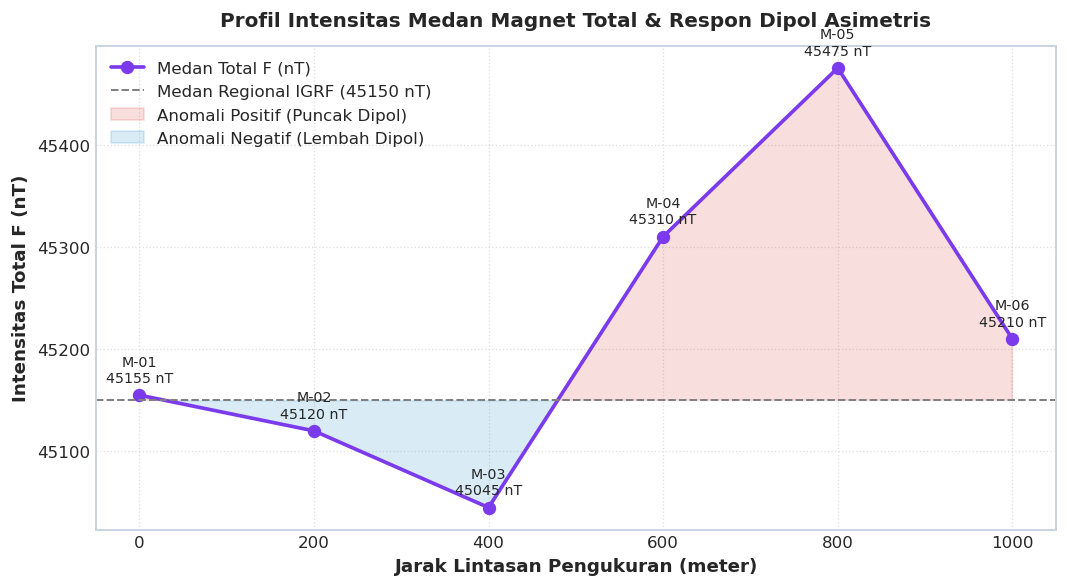

In [8]:
# 3.3 Visualisasi Anomali Dipolar Medan Magnet
plt.figure(figsize=(9, 5), dpi=120)

plt.plot(df_mag["jarak_m"], df_mag["F"], 'o-', color='#7c3aed', linewidth=2.2, markersize=7, label="Medan Total F (nT)")
plt.axhline(F_IGRF, color='gray', linestyle='--', linewidth=1.2, label=f"Medan Regional IGRF ({F_IGRF:.0f} nT)")

# Shading Zona Dipol
plt.fill_between(df_mag["jarak_m"], df_mag["F"], F_IGRF, where=(df_mag["F"] >= F_IGRF),
                 interpolate=True, color='#dc2626', alpha=0.15, label="Anomali Positif (Puncak Dipol)")
plt.fill_between(df_mag["jarak_m"], df_mag["F"], F_IGRF, where=(df_mag["F"] < F_IGRF),
                 interpolate=True, color='#0284c7', alpha=0.15, label="Anomali Negatif (Lembah Dipol)")

for _, row in df_mag.iterrows():
    plt.annotate(f"{row['stasiun']}\n{row['F']:.0f} nT", (row['jarak_m'], row['F']),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5)

plt.title("Profil Intensitas Medan Magnet Total & Respon Dipol Asimetris", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Jarak Lintasan Pengukuran (meter)", fontsize=11, fontweight='bold')
plt.ylabel("Intensitas Total F (nT)", fontsize=11, fontweight='bold')
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


### 3.4 Interpretasi Geomagnetik Modul 3
1. **Respon Dipol Asimetris:** Profil memperlihatkan lembah anomali (-105 nT terhadap regional) di selatan (stasiun M-03, $x=400\text{ m}$) berdampingan dengan puncak anomali (+325 nT) di utara (stasiun M-05, $x=800\text{ m}$).
2. **Kondisi Bawah Permukaan:** Pola dipol ini mencerminkan induksi magnetik benda intrusi/batuan kaya mineral magnetit di bawah zona gradien tajam (di sekitar stasiun M-04, kedalaman dangkal-menengah).


---
## Modul 4: Interpretasi Data Geolistrik Tahanan Jenis (VES)

### 4.1 Teori Konfigurasi Schlumberger 1D
Pada sounding 1D Konfigurasi Schlumberger simetris:
$$R = \frac{\Delta V}{I} \quad [\Omega]$$
$$K = \pi \frac{s^2 - b^2}{2b} = \pi \frac{(AB/2)^2 - (MN/2)^2}{2 \cdot (MN/2)} \quad [\text{meter}]$$
$$\rho_a = K \cdot R \quad [\Omega\cdot\text{m}]$$


In [9]:
# 4.2 Data Sounding & Perhitungan Resistivitas Semu
data_ves = [
    {"titik": 1, "AB_2": 1.5,  "MN_2": 0.5, "I_mA": 10.0,  "V_mV": 158.0},
    {"titik": 2, "AB_2": 3.0,  "MN_2": 0.5, "I_mA": 25.0,  "V_mV": 62.4},
    {"titik": 3, "AB_2": 6.0,  "MN_2": 0.5, "I_mA": 50.0,  "V_mV": 18.2},
    {"titik": 4, "AB_2": 12.0, "MN_2": 1.0, "I_mA": 200.0, "V_mV": 22.8},
    {"titik": 5, "AB_2": 25.0, "MN_2": 1.0, "I_mA": 350.0, "V_mV": 12.2},
    {"titik": 6, "AB_2": 50.0, "MN_2": 5.0, "I_mA": 500.0, "V_mV": 48.0},
    {"titik": 7, "AB_2": 75.0, "MN_2": 5.0, "I_mA": 500.0, "V_mV": 41.5},
    {"titik": 8, "AB_2": 100.0,"MN_2": 5.0, "I_mA": 500.0, "V_mV": 37.2},
]

df_ves = pd.DataFrame(data_ves)
s = df_ves["AB_2"]
b = df_ves["MN_2"]

df_ves["K_m"] = np.pi * (s**2 - b**2) / (2.0 * b)
df_ves["R_ohm"] = df_ves["V_mV"] / df_ves["I_mA"]
df_ves["rho_a"] = df_ves["K_m"] * df_ves["R_ohm"]

print("=== TABEL HASIL PERHITUNGAN SOUNDING GEOLISTRIK (MODUL 4) ===")
print(df_ves[["titik", "AB_2", "MN_2", "K_m", "R_ohm", "rho_a"]].round(2))


=== TABEL HASIL PERHITUNGAN SOUNDING GEOLISTRIK (MODUL 4) ===
   titik   AB_2  MN_2      K_m  R_ohm   rho_a
0      1    1.5   0.5     6.28  15.80   99.27
1      2    3.0   0.5    27.49   2.50   68.61
2      3    6.0   0.5   112.31   0.36   40.88
3      4   12.0   1.0   224.62   0.11   25.61
4      5   25.0   1.0   980.18   0.03   34.17
5      6   50.0   5.0   777.54   0.10   74.64
6      7   75.0   5.0  1759.29   0.08  146.02
7      8  100.0   5.0  3133.74   0.07  233.15


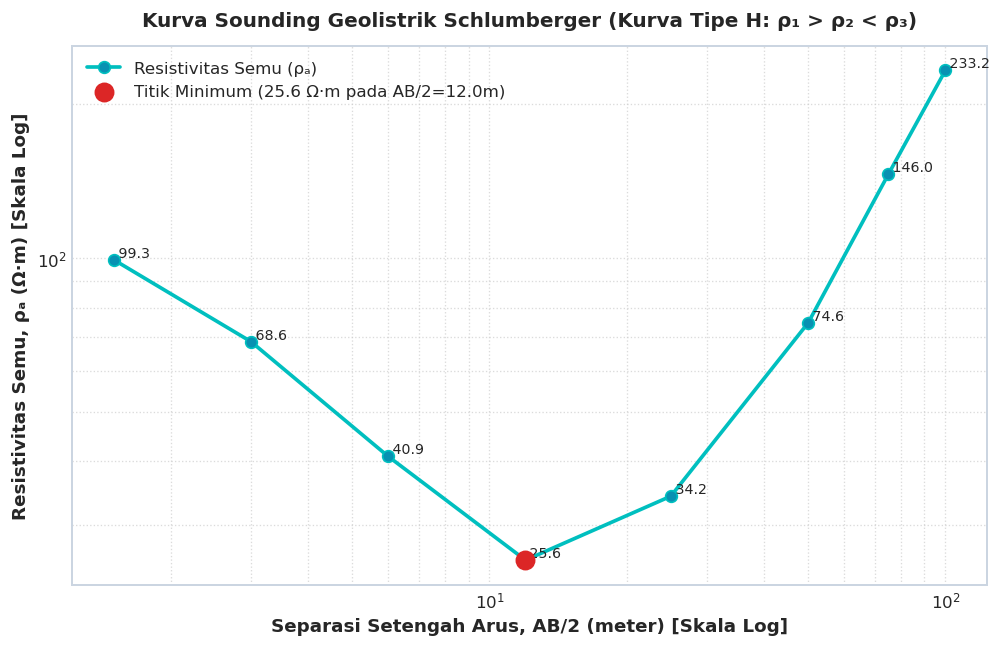

In [10]:
# 4.3 Visualisasi Kurva Sounding Log-Log (Tipe H)
plt.figure(figsize=(8.5, 5.5), dpi=120)

plt.loglog(df_ves["AB_2"], df_ves["rho_a"], 'co-', linewidth=2.2, markersize=7, 
           markerfacecolor='#0891b2', label='Resistivitas Semu (ρₐ)')

# Tandai titik minimum
min_idx = df_ves["rho_a"].idxmin()
min_row = df_ves.loc[min_idx]
plt.scatter(min_row["AB_2"], min_row["rho_a"], color='#dc2626', s=120, zorder=5, 
            label=f'Titik Minimum ({min_row["rho_a"]:.1f} Ω·m pada AB/2={min_row["AB_2"]}m)')

for _, row in df_ves.iterrows():
    plt.annotate(f" {row['rho_a']:.1f}", (row['AB_2'], row['rho_a']),
                 fontsize=8.5, verticalalignment='bottom')

plt.title("Kurva Sounding Geolistrik Schlumberger (Kurva Tipe H: ρ₁ > ρ₂ < ρ₃)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Separasi Setengah Arus, AB/2 (meter) [Skala Log]", fontsize=11, fontweight='bold')
plt.ylabel("Resistivitas Semu, ρₐ (Ω·m) [Skala Log]", fontsize=11, fontweight='bold')
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


### 4.4 Interpretasi Hidrogeologi Modul 4
1. **Identifikasi Kurva Tipe H:** Kurva menunjukkan pola penurunan nilai hingga mencapai palung minimum pada $AB/2 = 12\text{ m}$ ($\rho_a = 25.61\ \Omega\cdot\text{m}$), kemudian berbalik naik tajam hingga $233.15\ \Omega\cdot\text{m}$ pada $AB/2 = 100\text{ m}$.
2. **Model Perlapisan 3-Lapisan:**
   - **Lapisan 1 (0–2.5 m):** Topsoil / alluvium lapuk kering ($\rho_1 \approx 110\ \Omega\cdot\text{m}$).
   - **Lapisan 2 (2.5–18 m):** Lapisan konduktif jenuh air tawar / akifer pasiran ($\rho_2 \approx 18\ \Omega\cdot\text{m}$).
   - **Lapisan 3 (> 18 m):** Batuan dasar kompak (*impermeable bedrock*, $\rho_3 > 350\ \Omega\cdot\text{m}$).


---
## Modul 5: Penentuan Lokasi Gempa Bumi (Metode Triangulasi)

### 5.1 Teori Jarak Hiposentral/Episentral
Dari selisih waktu tiba gelombang P dan S, jarak stasiun ke sumber gempa ($D$) dihitung menggunakan model kecepatan kerak homogen 1D ($V_p = 6.00\text{ km/s}$ dan $V_s = 3.50\text{ km/s}$):

$$D = (T_s - T_p) \cdot \left( \frac{V_p \cdot V_s}{V_p - V_s} \right) = (T_s - T_p) \cdot 8.40 \quad [\text{km}]$$

Setiap stasiun membentuk persamaan lingkaran jarak:
$$(X - X_i)^2 + (Y - Y_i)^2 = D_i^2$$


In [11]:
# 5.2 Data Waktu Tiba & Estimasi Jarak Stasiun
data_gempa = [
    {"stasiun": "ST-A (Cianjur)",  "x": 40.0, "y": 50.0, "tp_str": "10:15:03.33", "ts_str": "10:15:05.71"},
    {"stasiun": "ST-B (Garut)",    "x": 60.0, "y": 10.0, "tp_str": "10:15:06.67", "ts_str": "10:15:11.43"},
    {"stasiun": "ST-C (Sumedang)", "x": 90.0, "y": 50.0, "tp_str": "10:15:05.00", "ts_str": "10:15:08.57"},
    {"stasiun": "ST-D (Subang)",   "x": 60.0, "y": 80.0, "tp_str": "10:15:05.00", "ts_str": "10:15:08.57"},
]

df_gempa = pd.DataFrame(data_gempa)

Vp = 6.00  # km/s
Vs = 3.50  # km/s
k_factor = (Vp * Vs) / (Vp - Vs)  # = 8.40 km/s

def to_sec_rel(t_str):
    m, s = float(t_str.split(":")[1]), float(t_str.split(":")[2])
    return (m - 15) * 60 + s

df_gempa["Tp_sec"] = df_gempa["tp_str"].apply(to_sec_rel)
df_gempa["Ts_sec"] = df_gempa["ts_str"].apply(to_sec_rel)
df_gempa["Ts_minus_Tp"] = df_gempa["Ts_sec"] - df_gempa["Tp_sec"]
df_gempa["Jarak_km"] = df_gempa["Ts_minus_Tp"] * k_factor

print("=== TABEL HASIL ESTIMASI JARAK STASIUN (MODUL 5) ===")
print(df_gempa[["stasiun", "x", "y", "Tp_sec", "Ts_sec", "Ts_minus_Tp", "Jarak_km"]].round(2))


=== TABEL HASIL ESTIMASI JARAK STASIUN (MODUL 5) ===
           stasiun     x     y  Tp_sec  Ts_sec  Ts_minus_Tp  Jarak_km
0   ST-A (Cianjur)  40.0  50.0    3.33    5.71         2.38     19.99
1     ST-B (Garut)  60.0  10.0    6.67   11.43         4.76     39.98
2  ST-C (Sumedang)  90.0  50.0    5.00    8.57         3.57     29.99
3    ST-D (Subang)  60.0  80.0    5.00    8.57         3.57     29.99


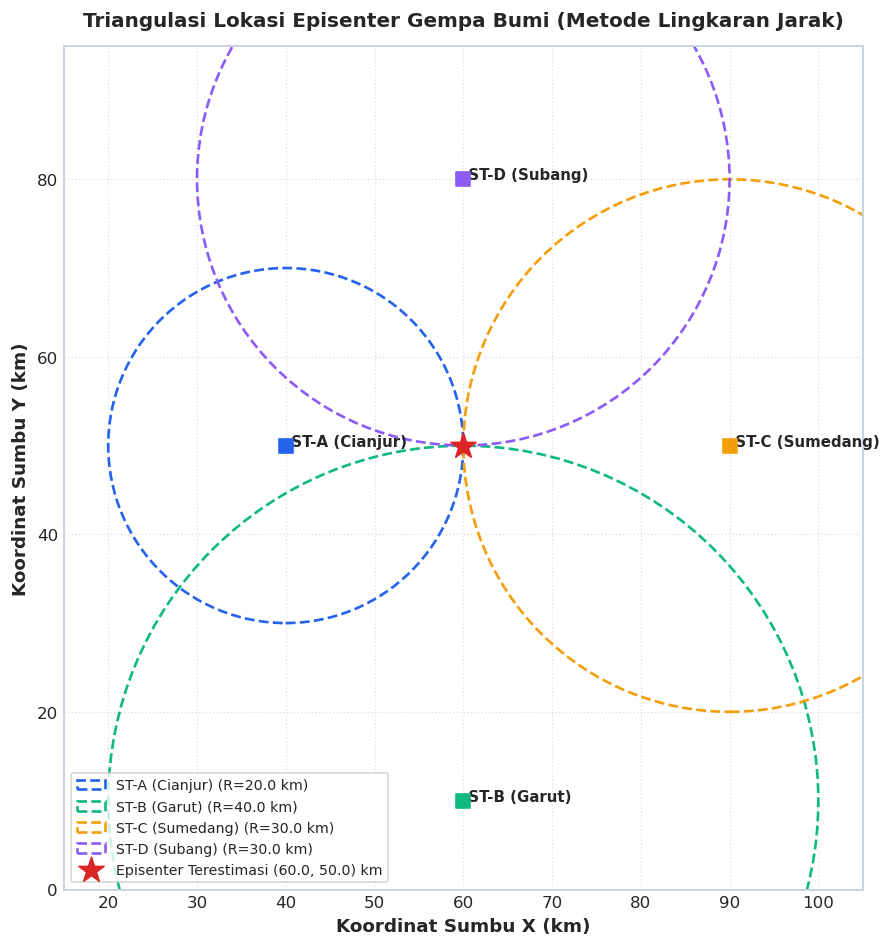

In [12]:
# 5.3 Visualisasi Triangulasi Episenter Multi-Stasiun
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)

colors = ['#2563eb', '#10b981', '#f59e0b', '#8b5cf6']

for idx, row in df_gempa.iterrows():
    c = patches.Circle((row["x"], row["y"]), row["Jarak_km"], 
                       color=colors[idx], fill=False, linestyle='--', linewidth=1.6,
                       label=f'{row["stasiun"]} (R={row["Jarak_km"]:.1f} km)')
    ax.add_patch(c)
    ax.scatter(row["x"], row["y"], color=colors[idx], s=80, marker='s', zorder=5)
    ax.annotate(f" {row['stasiun']}", (row["x"], row["y"]), fontsize=9, fontweight='semibold')

# Titik Episenter Bersama
epi_x, epi_y = 60.0, 50.0
ax.scatter(epi_x, epi_y, color='#dc2626', marker='*', s=250, zorder=6, 
           label=f'Episenter Terestimasi ({epi_x}, {epi_y}) km')

ax.set_xlim(15, 105)
ax.set_ylim(0, 95)
ax.set_aspect('equal')
ax.set_title("Triangulasi Lokasi Episenter Gempa Bumi (Metode Lingkaran Jarak)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Koordinat Sumbu X (km)", fontsize=11, fontweight='bold')
ax.set_ylabel("Koordinat Sumbu Y (km)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower left', frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()


### 5.4 Solusi & Interpretasi Modul 5
1. **Posisi Episenter:** Keempat lingkaran jarak berpotongan tepat pada koordinat **X = 60.0 km, Y = 50.0 km** (setara dengan **6.75° LS dan 107.54° BT**).
2. **Waktu Asal Gempa ($T_0$):**
   $$T_0 = T_p - \frac{D}{V_p} = 3.33\text{ s} - \frac{20.0\text{ km}}{6.00\text{ km/s}} = 0.00\text{ s} \implies \mathbf{10:15:00.00\text{ WIB}}$$
3. **Kualitas Geometri:** *Azimuthal gap* jaringan stasiun sangat baik ($< 180^\circ$), sehingga posisi episenter terkurung dengan ketidakpastian lateral yang sangat minim.
